In [2]:
import pandas as pd
import numpy as np
from scipy import stats
df = pd.read_excel("Cleaned_Sales_Dataset.xlsx")
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully!
Number of rows and columns: (1000, 15)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Year,Month,Month_Name
0,ORD100002,2025-02-25,CUST5529,Customer_227,30,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39,2025,2,February
1,ORD100003,2025-10-14,CUST3127,Customer_182,63,Male,Bengaluru,Book,Education,5,27906.16,139530.80,2025,10,October
2,ORD100004,2025-05-13,CUST8887,Customer_487,62,Female,Bengaluru,Book,Education,8,37491.06,299928.48,2025,5,May
3,ORD100005,2025-12-02,CUST2515,Customer_470,65,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24,2025,12,December
4,ORD100006,2025-11-20,CUST4796,Customer_380,44,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90,2025,11,November


In [4]:
print("Column names:")
print(df.columns.tolist())
print("\nMissing values:")
print(df[["Category", "Total_Sales"]].isnull().sum())
print("\nData types:")
print(df[["Category", "Total_Sales"]].dtypes)
print("\nProduct categories:")
print(df["Category"].value_counts())
print("\nSales summary:")
display(df.groupby("Category")["Total_Sales"].agg(
    ["count", "mean", "median", "std", "min", "max"]
))

Column names:
['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Total_Sales', 'Year', 'Month', 'Month_Name']

Missing values:
Category       0
Total_Sales    0
dtype: int64

Data types:
Category        object
Total_Sales    float64
dtype: object

Product categories:
Category
Electronics    354
Education      178
Furniture      159
Fashion        156
Grocery        153
Name: count, dtype: int64

Sales summary:


,count,mean,median,std,min,max
Category,,,,,,
Education,178,140627.468539,108468.935,116852.561339,1961.91,493677.5
Electronics,354,143442.321186,114521.400,117601.792606,1005.21,492174.1
Fashion,156,127153.178141,101570.320,105149.535726,2344.98,490866.4
Furniture,159,135355.732579,99838.560,111048.769818,767.61,438080.6
Grocery,153,145305.302484,109237.860,114918.086008,437.34,482551.9


In [5]:
anova_df = df[["Category", "Total_Sales"]].copy()
anova_df["Total_Sales"] = pd.to_numeric(
    anova_df["Total_Sales"], errors="coerce"
)
anova_df = anova_df.dropna(subset=["Category", "Total_Sales"])
print("Rows available for analysis:", len(anova_df))
print("\nObservations per category:")
print(anova_df["Category"].value_counts())
print("\nAverage sales by category:")
display(
    anova_df.groupby("Category")["Total_Sales"]
    .agg(["count", "mean", "std"])
    .round(2)
)

Rows available for analysis: 1000

Observations per category:
Category
Electronics    354
Education      178
Furniture      159
Fashion        156
Grocery        153
Name: count, dtype: int64

Average sales by category:


,count,mean,std
Category,,,
Education,178,140627.47,116852.56
Electronics,354,143442.32,117601.79
Fashion,156,127153.18,105149.54
Furniture,159,135355.73,111048.77
Grocery,153,145305.30,114918.09


In [6]:
sales_groups = [
    group["Total_Sales"].values
    for _, group in anova_df.groupby("Category")
]
f_statistic, p_value = stats.f_oneway(*sales_groups)
print("One-Way ANOVA Results")
print("---------------------")
print(f"F-statistic: {f_statistic:.4f}")
print(f"P-value: {p_value:.6f}")
alpha = 0.05
if p_value < alpha:
    print("\nDecision: Reject the null hypothesis.")
    print("Conclusion: There is statistically significant evidence")
    print("that mean sales differ across product categories.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("Conclusion: There is insufficient evidence that mean sales")
    print("differ across product categories.")

One-Way ANOVA Results
---------------------
F-statistic: 0.7171
P-value: 0.580286

Decision: Fail to reject the null hypothesis.
Conclusion: There is insufficient evidence that mean sales
differ across product categories.


In [7]:
print("Observations per category:")
print(anova_df.groupby("Category")["Total_Sales"].count())
groups = [
    group["Total_Sales"].values
    for _, group in anova_df.groupby("Category")
]
levene_stat, levene_p = stats.levene(*groups, center="median")
print("\nLevene's Test for Equal Variances")
print(f"Statistic: {levene_stat:.4f}")
print(f"P-value: {levene_p:.6f}")
if levene_p > 0.05:
    print("No statistically significant evidence of unequal variances.")
else:
    print("Evidence suggests the category variances may differ.")

Observations per category:
Category
Education      178
Electronics    354
Fashion        156
Furniture      159
Grocery        153
Name: Total_Sales, dtype: int64

Levene's Test for Equal Variances
Statistic: 0.9787
P-value: 0.418205
No statistically significant evidence of unequal variances.


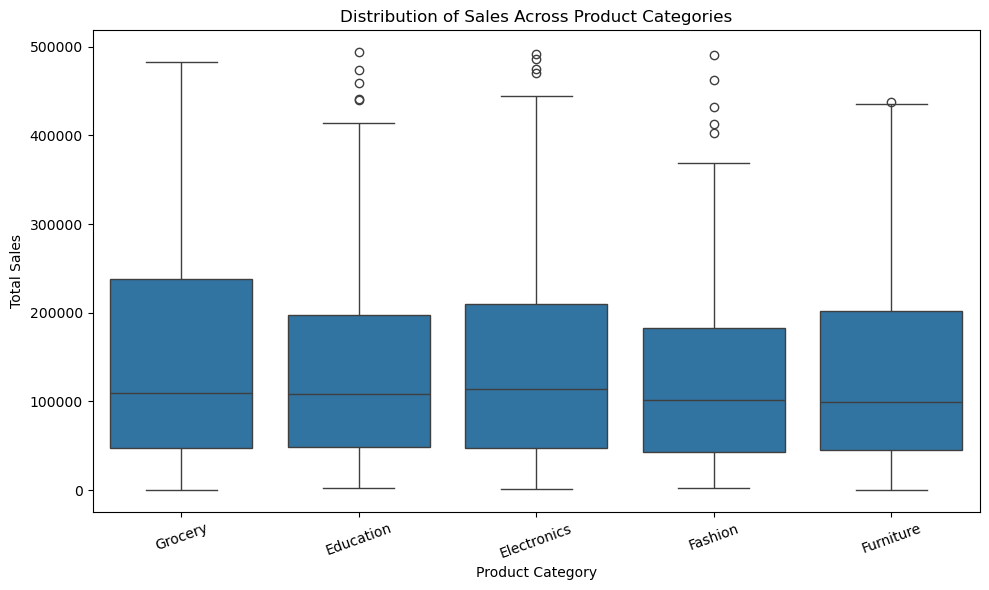

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=anova_df,
    x="Category",
    y="Total_Sales"
)
plt.title("Distribution of Sales Across Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [9]:
confidence_results = []
for category, group in anova_df.groupby("Category"):
    sales = group["Total_Sales"].dropna()
    n = len(sales)
    mean_sales = sales.mean()
    std_sales = sales.std(ddof=1)
    standard_error = std_sales / np.sqrt(n)
    t_critical = stats.t.ppf(0.975, df=n - 1)
    lower = mean_sales - t_critical * standard_error
    upper = mean_sales + t_critical * standard_error
    confidence_results.append({
        "Category": category,
        "Count": n,
        "Mean Sales": mean_sales,
        "95% CI Lower": lower,
        "95% CI Upper": upper
    })
confidence_df = pd.DataFrame(confidence_results)
display(confidence_df.round(2))

,Category,Count,Mean Sales,95% CI Lower,95% CI Upper
0,Education,178,140627.47,123343.00,157911.93
1,Electronics,354,143442.32,131149.49,155735.15
2,Fashion,156,127153.18,110522.99,143783.37
3,Furniture,159,135355.73,117961.61,152749.86
4,Grocery,153,145305.30,126949.97,163660.64


In [10]:
anova_summary = pd.DataFrame({
    "Metric": [
        "Test",
        "F-statistic",
        "P-value",
        "Significance level",
        "Decision",
        "Business conclusion",
        "Levene test p-value"
    ],
    "Result": [
        "One-way ANOVA",
        round(f_statistic, 4),
        round(p_value, 6),
        0.05,
        "Fail to reject the null hypothesis",
        "Insufficient evidence that mean sales differ across product categories",
        0.418205
    ]
})
anova_summary.to_csv(
    "ApexPlanet_Task4_Hypothesis_Testing_Summary.csv",
    index=False
)
print("Hypothesis-testing summary saved successfully!")
display(anova_summary)

Hypothesis-testing summary saved successfully!


,Metric,Result
0,Test,One-way ANOVA
1,F-statistic,0.7171
2,P-value,0.580286
3,Significance level,0.05
4,Decision,Fail to reject the null hypothesis
5,Business conclusion,Insufficient evidence that mean sales differ a...
6,Levene test p-value,0.418205


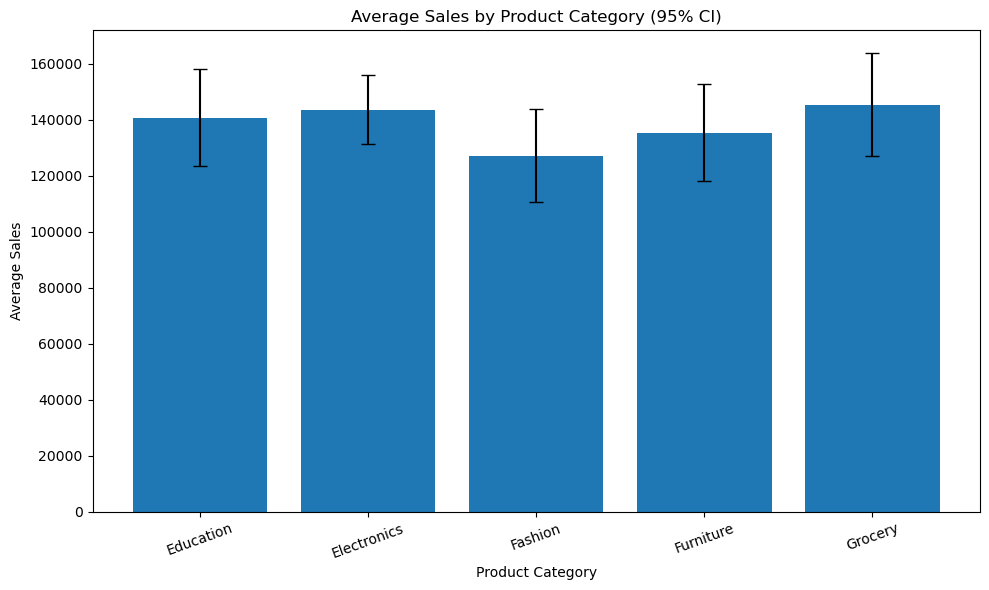

Chart saved successfully!


In [11]:
plt.figure(figsize=(10, 6))
plt.bar(
    confidence_df["Category"],
    confidence_df["Mean Sales"],
    yerr=[
        confidence_df["Mean Sales"] - confidence_df["95% CI Lower"],
        confidence_df["95% CI Upper"] - confidence_df["Mean Sales"]
    ],
    capsize=5
)
plt.title("Average Sales by Product Category (95% CI)")
plt.xlabel("Product Category")
plt.ylabel("Average Sales")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(
    "ApexPlanet_Task4_Average_Sales_Confidence_Intervals.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
print("Chart saved successfully!")

In [12]:
print("Skewness of sales by category:")
display(
    anova_df.groupby("Category")["Total_Sales"]
    .skew()
    .round(3)
    .rename("Sales Skewness")
    .to_frame()
)
print("\nPotential outliers by category (IQR method):")
for category, group in anova_df.groupby("Category"):
    sales = group["Total_Sales"]
    q1 = sales.quantile(0.25)
    q3 = sales.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = ((sales < lower) | (sales > upper)).sum()
    print(f"{category}: {outliers} potential outliers")

Skewness of sales by category:


,Sales Skewness
Category,
Education,1.055
Electronics,0.986
Fashion,1.210
Furniture,0.901
Grocery,0.794



Potential outliers by category (IQR method):
Education: 5 potential outliers
Electronics: 4 potential outliers
Fashion: 5 potential outliers
Furniture: 1 potential outliers
Grocery: 0 potential outliers


In [13]:
sales_groups = [
    group["Total_Sales"].values
    for _, group in anova_df.groupby("Category")
]
kw_statistic, kw_p_value = stats.kruskal(*sales_groups)
print("Kruskal-Wallis Test Results")
print("---------------------------")
print(f"H-statistic: {kw_statistic:.4f}")
print(f"P-value: {kw_p_value:.6f}")
if kw_p_value < 0.05:
    print("\nDecision: Reject the null hypothesis.")
    print("There is statistically significant evidence that")
    print("the sales distributions differ across categories.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence that the sales")
    print("distributions differ across categories.")

Kruskal-Wallis Test Results
---------------------------
H-statistic: 2.0066
P-value: 0.734538

Decision: Fail to reject the null hypothesis.
There is insufficient evidence that the sales
distributions differ across categories.


In [14]:
final_summary = pd.DataFrame([
    {
        "Test": "One-way ANOVA",
        "Statistic": f_statistic,
        "P-value": p_value,
        "Significance Level": 0.05,
        "Decision": "Fail to reject H0",
        "Interpretation": "No significant evidence of different category means"
    },
    {
        "Test": "Kruskal-Wallis",
        "Statistic": kw_statistic,
        "P-value": kw_p_value,
        "Significance Level": 0.05,
        "Decision": "Fail to reject H0",
        "Interpretation": "No significant evidence of different category distributions"
    },
    {
        "Test": "Levene's test",
        "Statistic": levene_stat,
        "P-value": levene_p,
        "Significance Level": 0.05,
        "Decision": "Fail to reject H0",
        "Interpretation": "No significant evidence of unequal variances"
    }
])
final_summary.to_csv(
    "ApexPlanet_Task4_Final_Statistical_Summary.csv",
    index=False
)
display(final_summary.round(6))
print("Final statistical summary saved successfully!")

,Test,Statistic,P-value,Significance Level,Decision,Interpretation
0,One-way ANOVA,0.717117,0.580286,0.05,Fail to reject H0,No significant evidence of different category ...
1,Kruskal-Wallis,2.006635,0.734538,0.05,Fail to reject H0,No significant evidence of different category ...
2,Levene's test,0.978652,0.418205,0.05,Fail to reject H0,No significant evidence of unequal variances


Final statistical summary saved successfully!
